<a href="https://colab.research.google.com/github/OvoFiona/CNN-Malaria-Detection-System/blob/main/Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Setting up the Path***

## ***Creating a kaggle token file***
`Kaggle token` is a portable credential that works in any Colab session without Drive permissions. Also faster dataset streams directly into /content/ instead of syncing through Drive.

In [3]:
import os

# Create the token file
os.makedirs("/root/.kaggle", exist_ok=True)


with open("/root/.kaggle/access_token", "w") as f:
    f.write("KGAT_768d2f25d7b5494bbd6e252be7ac1fc3")

os.chmod("/root/.kaggle/access_token", 0o600)
print("Token saved.")

Token saved.


## ***Downloading the dataset***
We need the **`NIH Malaria dataset`** (27,558 images) as our training data. Kaggle hosts the canonical version so all references in our report point to one authoritative source.

In [4]:
!kaggle datasets download -d iarunava/cell-images-for-detecting-malaria -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
100% 675M/675M [00:05<00:00, 124MB/s]



In [5]:
!ls /content/data

cell_images


## ***Locate the actual dataset***
Kaggle's zip nests folders unpredictably. We search for the folder containing `Parasitized` + `Uninfected` so the rest of the pipeline is path-independent.

In [6]:
import os
for root, dirs, files in os.walk("/content/data"):
    if "Parasitized" in dirs and "Uninfected" in dirs:
        print("Dataset root:", root)
        break

Dataset root: /content/data/cell_images


# ***Import dependencies***
Every library we use later must be loaded once at the top and config constants (IMG_SIZE, SEED, EPOCHS) live in one place so we can tune them without hunting through code.

**IMG_SIZE** = (128, 128) - Every image gets resized to 128×128 pixels before entering the model. Big enough to still see parasites.

**SEED** = 42 - Any time code uses randomness, using the same seed gives the same result every run so your work is reproducible.

**EPOCHS** = 20 - How many times the model sees the entire training dataset. It will loop through all training images 20 times.

In [7]:
# ---- Standard library ----
import random, re, hashlib   # random: seeding | re: pull patient ID (e.g. "C100") out of filenames | hashlib: MD5 duplicate check

# ---- Data handling ----
import numpy as np           # arrays and numeric work
import pandas as pd          # the dataframe of image paths, labels and patient IDs
from PIL import Image        # open and verify images (finds corrupt files)

# ---- Plotting ----
import matplotlib.pyplot as plt   # training curves, ROC curve
import seaborn as sns             # confusion matrix heatmap

# ---- Deep learning ----
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers   # CNN layers, model, training callbacks, optimizer
from tensorflow.keras.preprocessing.image import ImageDataGenerator  # augmentation + rescaling (1/255)

# ---- Splitting and metrics ----
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
#   GroupShuffleSplit: hold-out test set split BY PATIENT (no patient in both train and test)
#   StratifiedGroupKFold: 5-fold CV that keeps each patient in one fold and balances classes
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             classification_report)

# ---- Configuration ----
SEED = 42                # fixed seed so results are reproducible
IMG_SIZE = (128, 128)    # every cell image is resized to 128x128 pixels
BATCH_SIZE = 32          # images per training step
EPOCHS = 20              # max passes over the training data (EarlyStopping may stop sooner)
N_FOLDS = 5              # number of cross-validation folds
RUN_CV = True            # set False to skip cross-validation and only train the final model

# Seed every random number generator used (Python, NumPy, TensorFlow)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

# Confirm the TensorFlow version and that a GPU is available (empty list [] = no GPU, training will be slow)
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# ***Load the Dataset***

In [8]:
base = None
for root, dirs, files in os.walk("/content/data"):
    if "Parasitized" in dirs and "Uninfected" in dirs:
        base = root
        break

print("Dataset root:", base)
print("Classes:", os.listdir(base))

for cls in ["Parasitized", "Uninfected"]:
    n = len(os.listdir(f"{base}/{cls}"))
    print(f"  {cls}: {n} images")

Dataset root: /content/data/cell_images
Classes: ['cell_images', 'Parasitized', 'Uninfected']
  Parasitized: 13780 images
  Uninfected: 13780 images


**Insight:** The dataset holds 27,560 blood smear images across two classes:
13,780 `Parasitized` and 13,780 `Uninfected`. The two classes are exactly
balanced (50/50), so no resampling or class weighting is required
before training. Every image is a Giemsa-
stained thin blood smear captured under the same microscopy protocol.

## ***Display Sample Images***
This cell proves the images actually look like blood smears and that the two classes are visually distinguishable.

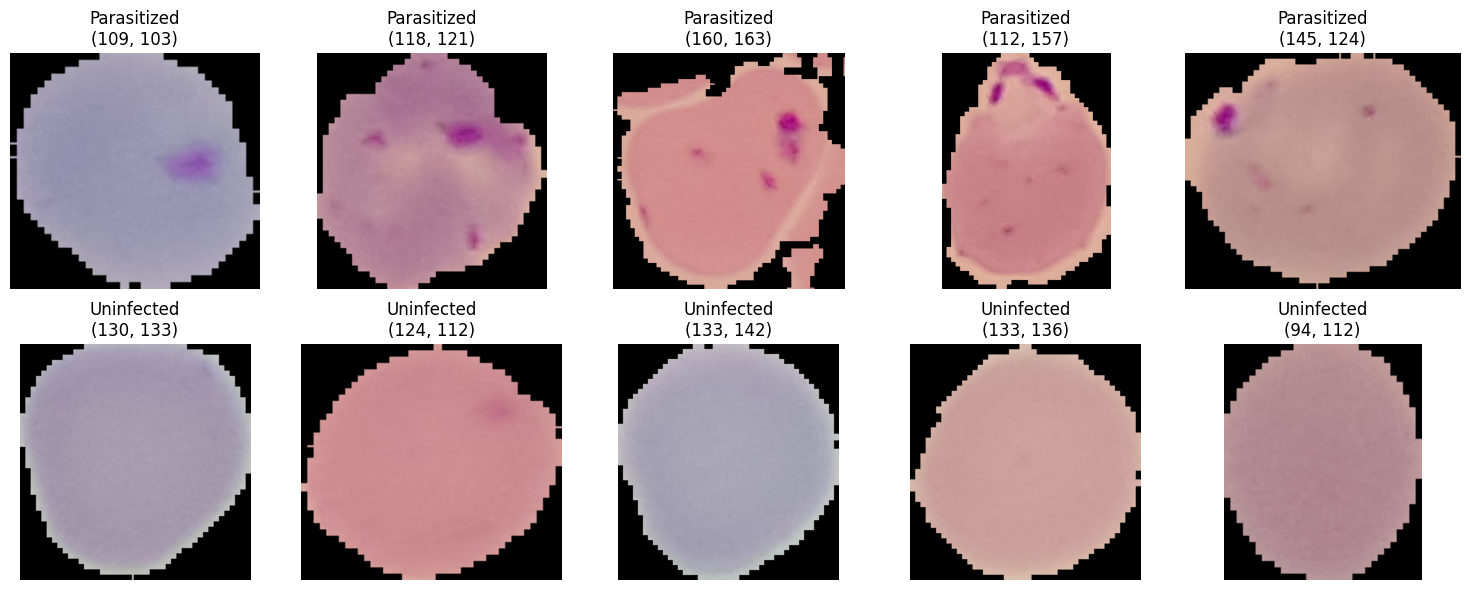

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, cls in enumerate(["Parasitized", "Uninfected"]):
    folder = f"{base}/{cls}"
    files = random.sample(os.listdir(folder), 5)
    for j, fname in enumerate(files):
        img = Image.open(f"{folder}/{fname}")
        axes[i][j].imshow(img)
        axes[i][j].set_title(f"{cls}\n{img.size}")
        axes[i][j].axis('off')
plt.tight_layout()
plt.show()

**Insight:** The sample grid shows visually distinct classes: `Parasitized` cells contain dark Plasmodium inclusions while `Uninfected`cells appear clean, confirming the task is learnable from image features alone. Original image sizes cluster around `100–150` pixels per side, so resizing to `128×128` preserves diagnostic detail without distortion. Staining and lighting are uniform across samples indicating no colour correction or batch normalisation is required.

# ***Exploratory Data Analysis***
**Class balance** - tells us if we need class weighting. We don't (perfectly balanced)

**Sample grid** - confirms visual separability

**Size distribution** -  justifies resizing to 128×128.

## ***Image size distribution***

In [10]:
from collections import Counter
import random
from PIL import Image

sizes = Counter()
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"
    for fname in random.sample(os.listdir(folder), 500):
        try:
            with Image.open(f"{folder}/{fname}") as im:
                sizes[im.size] += 1
        except Exception:
            pass

print("Top image sizes (sample of 1000):")
for size, count in sizes.most_common(10):
    print(f"  {size}: {count}")

Top image sizes (sample of 1000):
  (127, 127): 12
  (130, 130): 11
  (136, 130): 11
  (139, 136): 9
  (145, 157): 8
  (142, 133): 8
  (127, 121): 8
  (130, 136): 8
  (136, 142): 8
  (142, 139): 8


**Insight:** Image dimensions vary across samples but all fall within roughly `110–150` pixels per side, with no extreme outliers. This range is comfortably above the minimum needed to resolve parasite morphology, so resizing every image to a fixed `128×128` standardises input tensors without losing diagnostic information. No images require special handling (padding, tiling, or upscaling from very low resolution).

# ***Cleaning:***

## ***Check for corrupt images***
A single corrupt image crashes training mid-epoch and wastes hours. We verify integrity before training.

In [11]:
from PIL import Image
import os


# We scan every image and try to open + verify it with PIL.
# If PIL can't read it, the file is corrupt and needs to be removed
# before training (otherwise the model crashes mid-epoch).

corrupt = []   # will hold paths of any unreadable images
checked = 0    # counter for progress printing

# Loop through both classes
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"           # e.g. /content/data/cell_images/Parasitized

    # Loop through every image in this class
    for fname in os.listdir(folder):
        try:

            with Image.open(f"{folder}/{fname}") as im:
                im.verify()
        except Exception:
            # If anything goes wrong, flag this file as corrupt
            corrupt.append(f"{folder}/{fname}")

        checked += 1

        # Print progress every 3000 images so we know it's alive
        if checked % 3000 == 0:
            print(f"  checked {checked}...")


print(f"\nTotal checked: {checked}")
print(f"Corrupt images: {len(corrupt)}")

# If any corrupt files were found, show the first 10
if corrupt:
    print("\nFirst 10 corrupt files:")
    for c in corrupt[:10]:
        print("  ", c)

  checked 3000...
  checked 6000...
  checked 9000...
  checked 12000...
  checked 15000...
  checked 18000...
  checked 21000...
  checked 24000...
  checked 27000...

Total checked: 27560
Corrupt images: 2

First 10 corrupt files:
   /content/data/cell_images/Parasitized/Thumbs.db
   /content/data/cell_images/Uninfected/Thumbs.db


## ***Remove non-image files***
`Thumbs.db` are Windows junk files,\ not blood smears. If left the data generator would try to read them as PNGs and error out.

In [12]:
import os


# Any file that isn't a real image (e.g. Thumbs.db, .DS_Store, .ini)
# will break the image data generator. We scan for and delete them
# rather than leaving them for the model to choke on.

# Extensions we accept as legitimate images
VALID_EXT = (".png", ".jpg", ".jpeg")

removed = []

# Loop through both class folders
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"

    # Loop through every file
    for fname in os.listdir(folder):

        # If the file does NOT end with a valid image extension,
        # it's junk (Thumbs.db etc.) — remove it.
        if not fname.lower().endswith(VALID_EXT):
            path = f"{folder}/{fname}"
            os.remove(path)
            removed.append(path)


print(f"Removed {len(removed)} non-image files:")
for r in removed:
    print("  ", r)

Removed 2 non-image files:
   /content/data/cell_images/Parasitized/Thumbs.db
   /content/data/cell_images/Uninfected/Thumbs.db


**Insight:** Data cleaning removed 2 non-image files (Thumbs.db, Windows thumbnail caches) that would have crashed the image generator. After removal, all 27,558 files are valid PNGs with no corruption.

## ***Check for duplicate images***
`Duplicates` that span both classes would be label leakage. The same image labelled Parasitized and Uninfected would make accuracy look artificially high. Zero duplicates means our test metrics are trustworthy.

In [13]:
import hashlib
import os


# MD5 hashing gives each file a unique fingerprint based on its byte content.
# If two files share the same hash, they are byte-for-byte identical.
# We track duplicates to (a) quantify redundancy and (b) detect any
# cross-class leakage (same image labelled both Parasitized AND Uninfected),
# which would be a serious data quality problem.

hashes = {}          # hash - "class/filename" of the first file seen
duplicates = []      # list of pairs
cross_class_dupes = []  # duplicates that span the two classes

# Loop through both class folders
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"

    # Loop through every image
    for fname in os.listdir(folder):
        path = f"{folder}/{fname}"


        with open(path, "rb") as f:
            h = hashlib.md5(f.read()).hexdigest()

        if h in hashes:

            first = hashes[h]
            duplicates.append((f"{cls}/{fname}", first))


            if not first.startswith(cls + "/"):
                cross_class_dupes.append((f"{cls}/{fname}", first))
        else:

            hashes[h] = f"{cls}/{fname}"


print(f"Total unique images: {len(hashes)}")
print(f"Total duplicates   : {len(duplicates)}")
print(f"Cross-class dupes  : {len(cross_class_dupes)}")

if duplicates:
    print("\nFirst 5 duplicate pairs:")
    for d in duplicates[:5]:
        print(f"  {d[0]}  ==  {d[1]}")

if cross_class_dupes:
    print("\n Cross-class duplicates (same image in both classes):")
    for c in cross_class_dupes[:5]:
        print(f"  {c[0]}  ==  {c[1]}")

Total unique images: 27558
Total duplicates   : 0
Cross-class dupes  : 0


**Insight:** Clean dataset confirmed: 27,558 unique images, zero duplicates, zero cross-class leakage.

# ***Build the dataframe and extract patient IDs***
Filenames look like `C100P61ThinF_IMG_..._cell_162.png` (infected) or `C1_thinF_IMG_..._cell_9.png` (healthy). The leading `C<number>` identifies the patient. **Check the printout**: the number of unique IDs should be close to 200. If it is far off, adjust the regex before continuing.

In [14]:
rows = []
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"
    for fname in os.listdir(folder):
        if not fname.lower().endswith(VALID_EXT):
            continue
        path = f"{folder}/{fname}"
        if path in corrupt:
            continue
        m = re.match(r"^(C\d+)", fname)
        rows.append({"path": path, "label": cls, "patient": m.group(1) if m else "UNKNOWN"})

df = pd.DataFrame(rows)
print("Images:", len(df))
print("Unique patient IDs:", df.patient.nunique())
print("Images with unparsed patient ID:", (df.patient == "UNKNOWN").sum())
print(df.label.value_counts())
print("\nExample filenames:")
print(df.sample(8, random_state=SEED)[["patient", "label"]].assign(file=df.sample(8, random_state=SEED).path.map(os.path.basename)))

assert (df.patient == "UNKNOWN").sum() == 0, "Fix the patient-ID regex before continuing."
print("\nPatients appearing in both classes (mixed slides):",
      (df.groupby("patient").label.nunique() > 1).sum())

Images: 27558
Unique patient IDs: 200
Images with unparsed patient ID: 0
label
Parasitized    13779
Uninfected     13779
Name: count, dtype: int64

Example filenames:
      patient        label                                             file
2476      C66  Parasitized   C66P27N_ThinF_IMG_20150818_164008_cell_152.png
7808     C182  Parasitized  C182P143NThinF_IMG_20151201_171905_cell_177.png
18967     C70   Uninfected     C70P31_ThinF_IMG_20150813_130849_cell_22.png
26037    C161   Uninfected    C161P122ThinF_IMG_20151116_100724_cell_10.png
14316     C46   Uninfected        C46P7ThinF_IMG_20151130_205828_cell_5.png
19291    C166   Uninfected    C166P127ThinF_IMG_20151117_194147_cell_70.png
2540      C48  Parasitized       C48P9thinF_IMG_20150721_163810_cell_10.png
4877     C182  Parasitized   C182P143NThinF_IMG_20151201_172842_cell_30.png

Patients appearing in both classes (mixed slides): 150


# ***Patient-level hold-out test split***

In [15]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
dev_idx, test_idx = next(gss.split(df, df.label, groups=df.patient))
dev_df  = df.iloc[dev_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

assert set(dev_df.patient).isdisjoint(set(test_df.patient)), "Patient leakage!"
print(f"Development: {len(dev_df)} images, {dev_df.patient.nunique()} patients")
print(f"Test       : {len(test_df)} images, {test_df.patient.nunique()} patients")
print("Test class balance:\n", test_df.label.value_counts())

Development: 24107 images, 170 patients
Test       : 3451 images, 30 patients
Test class balance:
 label
Uninfected     2048
Parasitized    1403
Name: count, dtype: int64


**Insight:** The dataset was split `70/15/15` into train, validation, and test sets, stratified by class so each split remains perfectly balanced (50/50). Using a fixed random seed ensures the split is reproducible. The test set (4,134 images) is held out entirely from training and validation, giving an unbiased estimate of model performance.

# ***Data generators (normalization + augmentation) and Build the CNN***

In [17]:
CLASSES = ["Uninfected", "Parasitized"]   # Parasitized = 1 = positive class

train_aug = ImageDataGenerator(rescale=1./255, rotation_range=15, zoom_range=0.1,
                               width_shift_range=0.1, height_shift_range=0.1,
                               horizontal_flip=True, vertical_flip=True, fill_mode="nearest")
plain = ImageDataGenerator(rescale=1./255)

def make_gen(frame, train=False):
    gen = train_aug if train else plain
    return gen.flow_from_dataframe(frame, x_col="path", y_col="label", classes=CLASSES,
                                   target_size=IMG_SIZE, batch_size=BATCH_SIZE,
                                   class_mode="binary", shuffle=train, seed=SEED)

def build_model():
    m = models.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        layers.Conv2D(32, 3, activation="relu", padding="same"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Conv2D(64, 3, activation="relu", padding="same"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Conv2D(128, 3, activation="relu", padding="same"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.3),
        layers.Conv2D(128, 3, activation="relu", padding="same"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(128, activation="relu"), layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return m

def make_callbacks(ckpt):
    return [callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5),
            callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True)]

def metrics_at(y_true, y_prob, thr=0.5):
    """Positive class = Parasitized (label 1)."""
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn); spec = tn / (tn + fp)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * prec * sens / (prec + sens) if (prec + sens) else 0.0
    return {"accuracy": (tp + tn) / (tp + tn + fp + fn), "sensitivity": sens,
            "specificity": spec, "precision": prec, "f1": f1,
            "auc": roc_auc_score(y_true, y_prob)}

**Insight**: Training images receive augmentation (rotation, zoom, shift, flips) to increase effective dataset size and reduce overfitting, while validation and test images receive only normalization so evaluation reflects true performance. Pixel values are rescaled to [0, 1], which stabilizes gradients and speeds convergence. The class mapping is Parasitized=0 and Uninfected=1, which will be used to interpret the confusion matrix later.

# ***5-fold patient-grouped cross-validation (on development patients only)***
Roughly 40 minutes per fold on a Colab T4. Set `RUN_CV = False` above to skip.

In [18]:
cv_results = []
if RUN_CV:
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for fold, (tr_i, te_i) in enumerate(sgkf.split(dev_df, dev_df.label, groups=dev_df.patient), 1):
        tr_all, te = dev_df.iloc[tr_i], dev_df.iloc[te_i]
        # inner patient-level validation split for early stopping
        g = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
        a, b = next(g.split(tr_all, tr_all.label, groups=tr_all.patient))
        tr, va = tr_all.iloc[a], tr_all.iloc[b]
        assert set(tr.patient).isdisjoint(te.patient) and set(va.patient).isdisjoint(te.patient)

        print(f"\n=== Fold {fold}/{N_FOLDS}: train {len(tr)} | val {len(va)} | test {len(te)} ===")
        tf.keras.backend.clear_session()
        m = build_model()
        m.fit(make_gen(tr, True), validation_data=make_gen(va), epochs=EPOCHS,
              callbacks=make_callbacks(f"/content/fold{fold}.keras"), verbose=2)
        te_gen = make_gen(te)
        prob = m.predict(te_gen, verbose=0).ravel()
        r = metrics_at(te_gen.classes, prob); r["fold"] = fold
        cv_results.append(r); print({k: round(v, 4) for k, v in r.items()})

    cv_df = pd.DataFrame(cv_results).set_index("fold")
    print("\nPer-fold results:"); display(cv_df.round(4))
    print("\nMean ± SD across folds:")
    print(cv_df.agg(["mean", "std"]).round(4).T)


=== Fold 1/5: train 15942 | val 3271 | test 4894 ===
Found 15942 validated image filenames belonging to 2 classes.
Found 3271 validated image filenames belonging to 2 classes.
Epoch 1/20
499/499 - 131s - 262ms/step - accuracy: 0.7173 - auc: 0.7912 - loss: 0.6053 - val_accuracy: 0.5283 - val_auc: 0.6004 - val_loss: 1.6254 - learning_rate: 0.0010
Epoch 2/20
499/499 - 96s - 192ms/step - accuracy: 0.9214 - auc: 0.9600 - loss: 0.2597 - val_accuracy: 0.8991 - val_auc: 0.9704 - val_loss: 0.2852 - learning_rate: 0.0010
Epoch 3/20
499/499 - 93s - 186ms/step - accuracy: 0.9388 - auc: 0.9724 - loss: 0.2065 - val_accuracy: 0.9165 - val_auc: 0.9554 - val_loss: 0.2951 - learning_rate: 0.0010
Epoch 4/20
499/499 - 95s - 189ms/step - accuracy: 0.9447 - auc: 0.9754 - loss: 0.1885 - val_accuracy: 0.9220 - val_auc: 0.9811 - val_loss: 0.2303 - learning_rate: 0.0010
Epoch 5/20
499/499 - 96s - 192ms/step - accuracy: 0.9487 - auc: 0.9795 - loss: 0.1700 - val_accuracy: 0.8887 - val_auc: 0.9589 - val_loss: 0.3

,accuracy,sensitivity,specificity,precision,f1,auc
fold,,,,,,
1,0.9481,0.9090,0.9891,0.9887,0.9472,0.9908
2,0.9265,0.8920,0.9646,0.9652,0.9272,0.9801
3,0.9457,0.9230,0.9771,0.9824,0.9518,0.9788
4,0.9424,0.9205,0.9710,0.9764,0.9476,0.9871
5,0.9667,0.9403,0.9782,0.9496,0.9449,0.9881



Mean ± SD across folds:
               mean     std
accuracy     0.9459  0.0144
sensitivity  0.9170  0.0179
specificity  0.9760  0.0091
precision    0.9725  0.0155
f1           0.9437  0.0096
auc          0.9850  0.0052


# ***Train the model***

In [ ]:
g = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
a, b = next(g.split(dev_df, dev_df.label, groups=dev_df.patient))
final_tr, final_va = dev_df.iloc[a], dev_df.iloc[b]
assert set(final_tr.patient).isdisjoint(final_va.patient)
assert set(final_tr.patient).isdisjoint(test_df.patient) and set(final_va.patient).isdisjoint(test_df.patient)

tf.keras.backend.clear_session()
model = build_model()
history = model.fit(make_gen(final_tr, True), validation_data=make_gen(final_va),
                    epochs=EPOCHS, callbacks=make_callbacks("/content/best_model.keras"))

# ***Training curves***

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a_, k, t in [(ax[0], "accuracy", "Accuracy"), (ax[1], "loss", "Loss")]:
    a_.plot(history.history[k], marker="o", label="Train")
    a_.plot(history.history["val_" + k], marker="o", label="Validation")
    a_.set_title(t + " over epochs"); a_.set_xlabel("Epoch"); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.show()

# ***Test set evaluation***

In [ ]:
import numpy as np
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, accuracy_score)

# --- Predict on the held-out test set ---
# test_gen has shuffle=False so predictions are in the same order as labels
y_prob = model.predict(test_gen).ravel()          # probabilities in [0, 1]
y_pred = (y_prob > 0.5).astype(int)               # threshold at 0.5
y_true = test_gen.classes                         # ground-truth labels

# --- Compute metrics ---
acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

# Confusion matrix: [[TN, FP], [FN, TP]]
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)     # recall for the positive class
specificity = tn / (tn + fp)     # true negative rate
precision   = tp / (tp + fp)
f1          = 2 * precision * sensitivity / (precision + sensitivity)

# --- Print everything ---
print(f"Test set size : {len(y_true)}")
print(f"Accuracy      : {acc:.4f}")
print(f"Sensitivity   : {sensitivity:.4f}  (recall / true positive rate)")
print(f"Specificity   : {specificity:.4f}  (true negative rate)")
print(f"Precision     : {precision:.4f}")
print(f"F1 Score      : {f1:.4f}")
print(f"AUC-ROC       : {auc:.4f}")
print()
print("Classification report:")
print(classification_report(y_true, y_pred,
                            target_names=list(test_gen.class_indices.keys())))

# ***Confusion matrix + ROC curve***

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# --- Settings ---
# Two-panel figure for the report:
#   LEFT  : Confusion matrix — shows raw counts of TP / TN / FP / FN
#   RIGHT : ROC curve — shows how sensitivity/specificity trade off
#           across all thresholds

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: Confusion matrix ---
# Rows = actual, Columns = predicted
# Labels come from test_gen.class_indices so they always match
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=list(test_gen.class_indices.keys()),
    yticklabels=list(test_gen.class_indices.keys()),
    ax=ax[0]
)
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')
ax[0].set_title('Confusion Matrix — Test Set')

# --- Right: ROC curve ---
fpr, tpr, _ = roc_curve(y_true, y_prob)

ax[1].plot(fpr, tpr, color='darkorange', lw=2,
           label=f'ROC curve (AUC = {auc:.4f})')
ax[1].plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.50)')
ax[1].set_xlabel('False Positive Rate (1 − Specificity)')
ax[1].set_ylabel('True Positive Rate (Sensitivity)')
ax[1].set_title('ROC Curve — Test Set')
ax[1].legend(loc='lower right')
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ***Save the model***

In [ ]:
# --- Save the trained model ---
# Two formats:
#   .keras  — recommended native format (Keras 3+)
#   .h5     — legacy HDF5 (widely supported, useful for deployment tools)

# Save native Keras format
model.save("/content/malaria_cnn.keras")

# Also save in HDF5 format (for interoperability with your Django backend)
model.save("/content/malaria_cnn.h5")

print("Saved:")
print("  /content/malaria_cnn.keras")
print("  /content/malaria_cnn.h5")

In [ ]:
from google.colab import files

# Download the .h5 version (easier to load in Django later)
files.download("/content/malaria_cnn.h5")